In [25]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import torch
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
import matplotlib.pyplot as plt
import torch.nn as nn

In [26]:
torch.manual_seed(42) # reproducebility
df = pd.read_csv("/content/fmnist_dataset_small.csv")
df

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,9,0,0,0,0,0,0,0,0,0,...,0,7,0,50,205,196,213,165,0,0
1,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,...,142,142,142,21,0,3,0,0,0,0
3,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,8,0,0,0,0,0,0,0,0,0,...,213,203,174,151,188,10,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,1,0,0,0,0,0,0,0,0,0,...,69,12,0,0,0,0,0,0,0,0
5996,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5997,8,0,0,0,0,0,0,0,0,0,...,39,47,2,0,0,29,0,0,0,0
5998,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [27]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [28]:
# Example:
fruits = ["Apple", "banana", "mango"]
for i, fruit in enumerate(fruits):
  print(i, fruit)

0 Apple
1 banana
2 mango


Text(0.5, 0.98, 'First 16 Images')

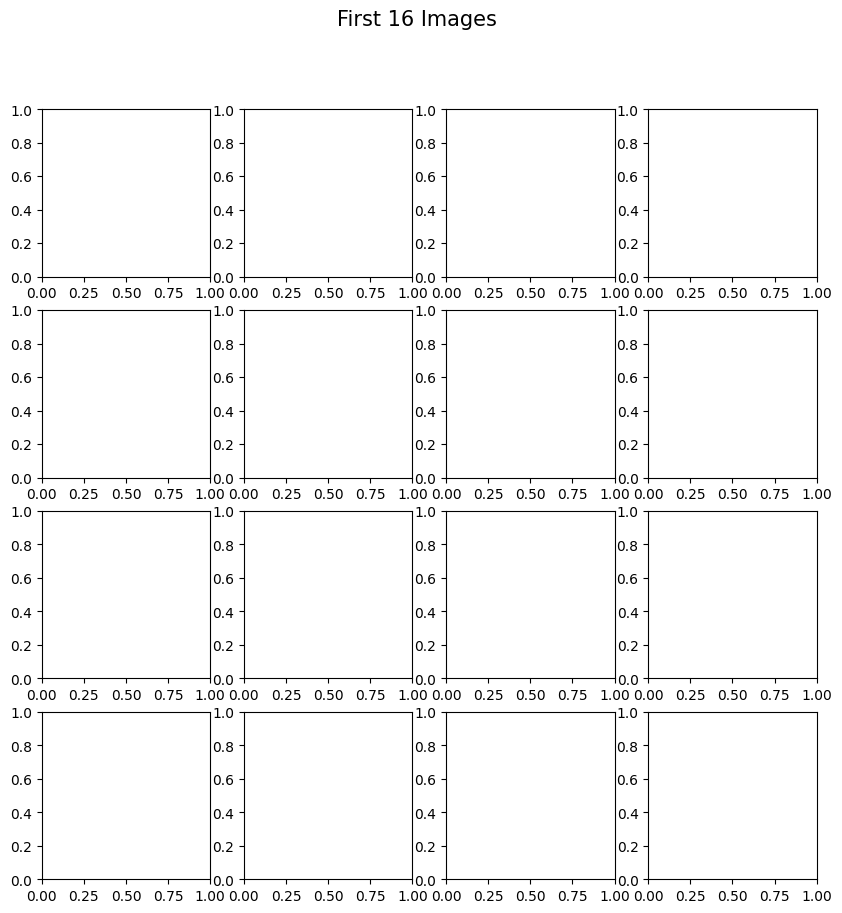

In [29]:
fig, axes = plt.subplots(4,4, figsize=(10,10))
fig.suptitle("First 16 Images", fontsize=15)

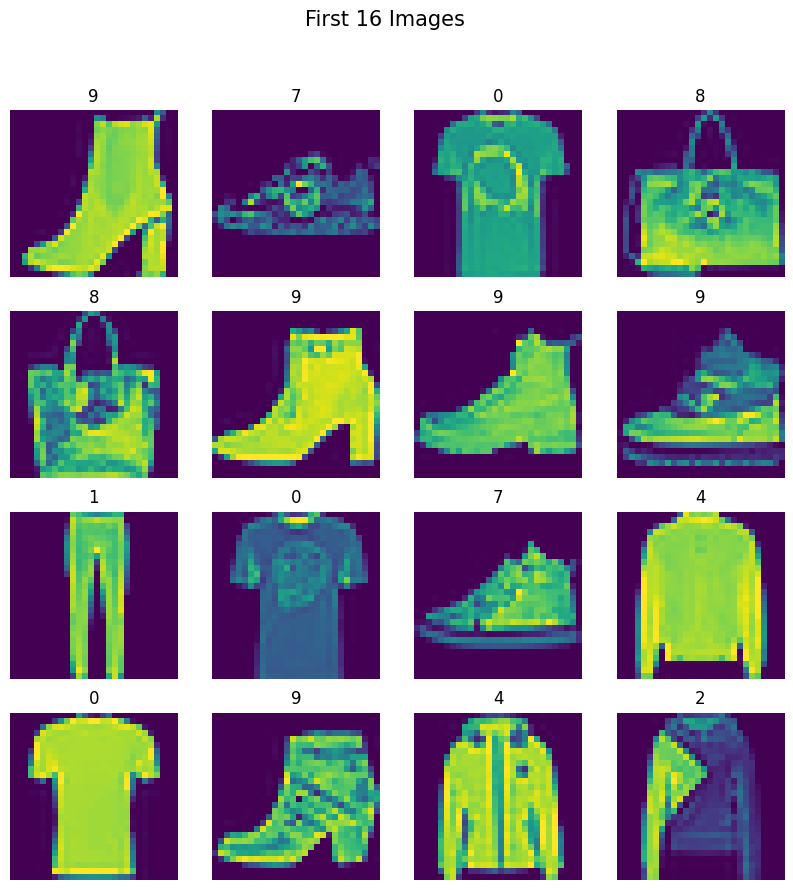

In [30]:
fig, axes = plt.subplots(4,4, figsize=(10,10))
fig.suptitle("First 16 Images", fontsize=15)
for i, ax in enumerate(axes.flat):
  img = df.iloc[i,1:].values.reshape(28,28)
  ax.imshow(img)
  ax.axis('off')
  ax.set_title(df.iloc[i,0])
plt.show()

# architecture

In [31]:
len(df.columns)

785

In [32]:
len(df['label'].unique())

10



```
Architecture is:
input layer -> 785-1=784
output layer -> 10
so, output activation function: Softmax
```





```
plan for the ANN:
input layer --> 784
hidden layer --> 128
hidden layer --> 64
output layer --> 10

```



# Basic operations:

In [33]:
X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [34]:
# scaling:
X_train = X_train / 255.0
X_test = X_test / 255.0

# Custom Dataset

In [35]:
class CustomDataset(Dataset):
  def __init__(self, features, labeles):
    self.features = torch.tensor(features, dtype=torch.float32)
    self.labeles = torch.tensor(labeles, dtype=torch.long)
  def __len__(self):
    return len(self.features)
  def __getitem__(self, index):
    return self.features[index], self.labeles[index]



In [36]:
train_dataset = CustomDataset(X_train, y_train)
test_dataset = CustomDataset(X_test, y_test)

# loader

In [37]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, pin_memory=True)  # don't shuffle in test

# NN class

In [38]:
class MySampleNN(nn.Module):
  def __init__(self, num_features):
    super().__init__()

    self.model = nn.Sequential(
        nn.Linear(num_features, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 10)
        # no need to use AF here as we are using CrossEntropyLoss
    )
  def forward(self, X):
    return self.model(X)





# instatiate Model



In [39]:
epochs = 15
learning_rate = 0.1

In [40]:
model = MySampleNN(X_train.shape[1])
model = model.to(device)

In [41]:
# loss function define
criterion = nn.CrossEntropyLoss() # this: Log-Softmax: logits-কে log-probability-তে রূপান্তর করে।


In [42]:
# optimizer
optimizer = optim.SGD(model.parameters(),lr = learning_rate)

# Trainning Loop

In [43]:
for epoch in range(epochs):
  each_epoch_total_loss = 0
  for batch_features, batch_label in train_loader:
    # move data to gpu
    batch_features = batch_features.to(device)
    batch_label = batch_label.to(device)
    # forward pass
    out = model(batch_features)
    loss = criterion(out, batch_label)

    # backward pass
    optimizer.zero_grad()
    loss.backward()

    # update weights
    optimizer.step()
    each_epoch_total_loss += loss.item()
  print(f"Epoch: {epoch+1}, Loss: {each_epoch_total_loss/len(train_loader)}")



Epoch: 1, Loss: 1.3216368587811789
Epoch: 2, Loss: 0.779336541891098
Epoch: 3, Loss: 0.6427524608373641
Epoch: 4, Loss: 0.5751657414436341
Epoch: 5, Loss: 0.5278772541880608
Epoch: 6, Loss: 0.49531100074450174
Epoch: 7, Loss: 0.46192684868971506
Epoch: 8, Loss: 0.4355265040695667
Epoch: 9, Loss: 0.41890643616517387
Epoch: 10, Loss: 0.39741520086924237
Epoch: 11, Loss: 0.38665723502635957
Epoch: 12, Loss: 0.37127780785163245
Epoch: 13, Loss: 0.34902072985967
Epoch: 14, Loss: 0.3476298343638579
Epoch: 15, Loss: 0.315855147143205


# Evaluation

In [44]:
model.eval()
total = 0
correct = 0


with torch.no_grad():
  for batch_features, batch_label in test_loader:
    # to gpu
    batch_features = batch_features.to(device)
    batch_label = batch_label.to(device)

    out = model(batch_features)
    _, predicted = torch.max(out.data, 1)

    total = total + batch_label.shape[0]
    correct += (predicted == batch_label).sum().item()
print(f"total num: {total}")
print(f"correct num: {correct}")
print(f"accuracy: {correct/total}")

total num: 1200
correct num: 989
accuracy: 0.8241666666666667
